# ByteGuard: Exploratory Data Analysis (EDA)
This notebook covers the exploratory data analysis for the **ByteGuard Malware Image Classification** project (CT-264 Programming for Artificial Intelligence).
### Objectives:
- Inspect preprocessed dataset splits (5,160 records).
- Analyze class distributions and verify class imbalance mitigation (capping oversized classes like Allaple).
- Visualize raw byte-to-image texture characteristics across different malware families.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set plotting style\n
sns.set_theme(style='whitegrid')

## 1. Load Preprocessed Data Splits

In [2]:
splits_dir = '../data/splits'
X_train = np.load(os.path.join(splits_dir, 'X_train.npy'))
y_train = np.load(os.path.join(splits_dir, 'y_train.npy'))
X_val = np.load(os.path.join(splits_dir, 'X_val.npy'))
y_val = np.load(os.path.join(splits_dir, 'y_val.npy'))
X_test = np.load(os.path.join(splits_dir, 'X_test.npy'))
y_test = np.load(os.path.join(splits_dir, 'y_test.npy'))

print(f'Training Set Shape: {X_train.shape}, Labels: {y_train.shape}')
print(f'Validation Set Shape: {X_val.shape}')
print(f'Test Set Shape: {X_test.shape}')

Training Set Shape: (3612, 64, 64, 1), Labels: (3612,)
Validation Set Shape: (516, 64, 64, 1)
Test Set Shape: (1032, 64, 64, 1)


## 2. Malware Family Distribution Analysis

C:\Users\razaj\AppData\Local\Temp\ipykernel_18696\2574192561.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_dist, x='Malware Family', y='Sample Count', palette='viridis')


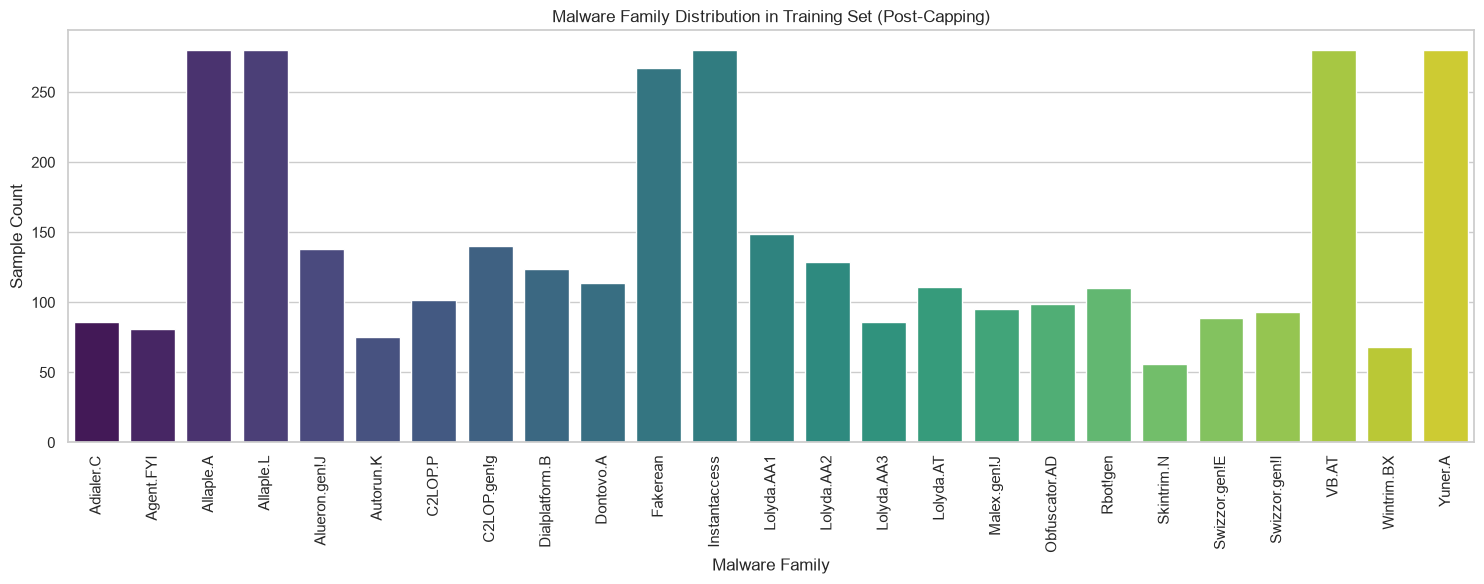

In [3]:
raw_dir = '../data/raw/malimg_paper_dataset_imgs'
class_names = [f for f in sorted(os.listdir(raw_dir)) if os.path.isdir(os.path.join(raw_dir, f))]

# Count samples per class in training set\n
unique_classes, counts = np.unique(y_train, return_counts=True)
df_dist = pd.DataFrame({'Malware Family': [class_names[i] for i in unique_classes], 'Sample Count': counts})

plt.figure(figsize=(15, 6))
sns.barplot(data=df_dist, x='Malware Family', y='Sample Count', palette='viridis')
plt.xticks(rotation=90)
plt.title('Malware Family Distribution in Training Set (Post-Capping)')
plt.tight_layout()
plt.show()

## 3. Visualizing Malware Image Textures

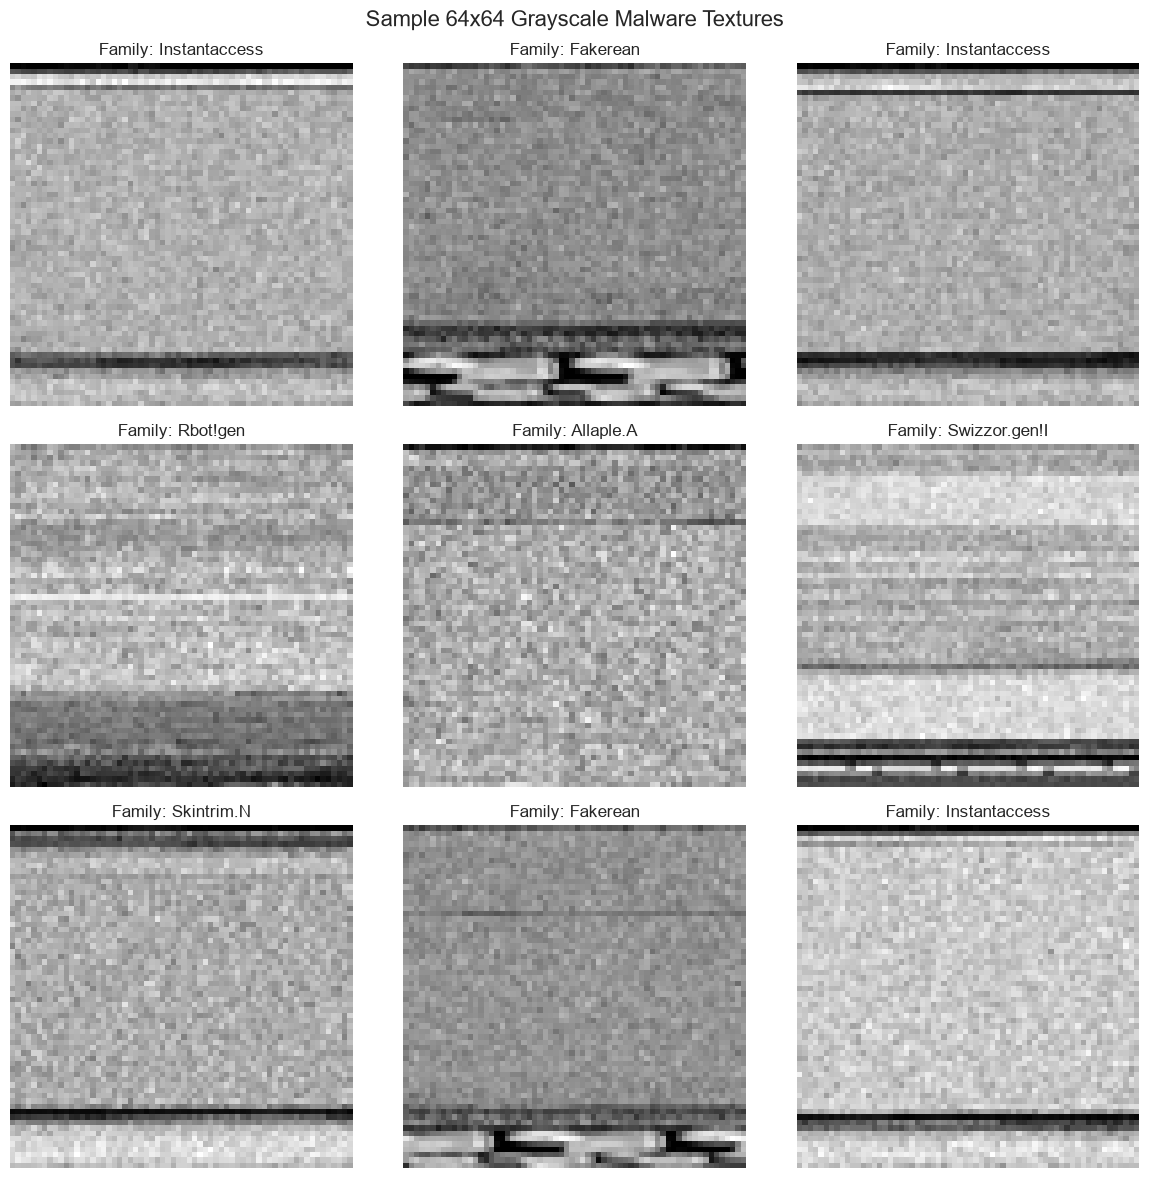

In [4]:
plt.figure(figsize=(12, 12))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[i].reshape(64, 64), cmap='gray')
    plt.title(f'Family: {class_names[y_train[i]]}')
    plt.axis('off')
plt.suptitle('Sample 64x64 Grayscale Malware Textures', fontsize=16)
plt.tight_layout()
plt.show()